# Drift: the PSI rules, their benchmark and the false-alarm rate

**Question:** How often do the PSI rules of thumb raise a false alarm when nothing has changed, and how large a shift do they, the chi-square benchmark and the Kolmogorov-Smirnov test actually detect?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the rate and the size of every test)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say why the population stability index (PSI) has a noise floor that depends only on the sample sizes, and compute it together with the 5% benchmark of the engine;
- read the PSI, its conventional band and its p-value on three datasets and see when the band and the benchmark disagree;
- measure the false-alarm rate of the two rules of thumb when nothing has changed and see how it falls with the sample size;
- draw the power of the rules, the chi-square benchmark and the Kolmogorov-Smirnov test against the size of the shift;
- rerun cells of Table 4 of Yurdakul and Naranjo (2020) with the engine and tell drift from miscalibration.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `drift` family of case C22, validating the validator. Its `stability` panel draws two samples of one variable after the design of Yurdakul and Naranjo (2020): a base sample from $N(0, 8^2)$ binned in its ten population deciles, and a current sample whose mean is shifted by a fraction of a standard deviation, on a ladder from 0 to 0.5. Its `calibration` panel shifts the covariates of a logistic portfolio by the same amounts while the model keeps its true coefficients. Every dataset is drawn by a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`). The family also holds, under `golden`, the 54 cells of the paper's Table 4, quoted from the paper.

- **File read:** `data/derived/C22/drift.json`, keys `outputs` (simulations, generators, ladder, published cells) and `provenance`.
- **What is taken from it:** the ladder, the configuration and seed of each rung and the published rates.

The next cell loads the file and prints the ladder with the engine versions.

In [2]:
# Load the drift family and index its simulations by key
LANG = "en"
ROOT = Path("../../..").resolve()
drift = json.loads((ROOT / "data" / "derived" / "C22" / "drift.json").read_text(encoding="utf-8"))
out = drift["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]
print("shifts of the ladder, in standard deviations:", ladder)
print("baked by riskvalidation", drift["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)

shifts of the ladder, in standard deviations: [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

**The PSI.** With $B$ fixed bins, development proportions $e_i$ and current proportions $a_i$, the index is

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i},$$

the symmetrised Kullback-Leibler divergence. Practice reads it with two rules of thumb, 0.10 for a small and 0.25 for a significant change. Yurdakul and Naranjo show that for samples of $n$ and $m$ observations the index is approximately $(1/n + 1/m)\,\chi^2_{B-1}$ when nothing changes, so its expected value is $(1/n + 1/m)(B-1)$ and a test of level $\alpha$ rejects above $(1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$. A fixed band ignores the sample size and the benchmark follows it. The steps compute both, draw datasets, measure the false alarms and the power of the rules, rerun the paper's table and contrast drift with miscalibration.

### Step 1: the noise floor of the PSI

With ten bins, the expected PSI when nothing changes is $(1/n + 1/m)\cdot 9$. The engine's `psi_benchmark` returns the 5% benchmark for given sample sizes. The next cell prints both for four equal sample sizes, and draws them against the two rules of thumb on a logarithmic axis.

n = m =  100 | expected PSI under no change 0.1800 | 5% benchmark 0.3384
n = m =  200 | expected PSI under no change 0.0900 | 5% benchmark 0.1692
n = m =  400 | expected PSI under no change 0.0450 | 5% benchmark 0.0846
n = m = 1000 | expected PSI under no change 0.0180 | 5% benchmark 0.0338


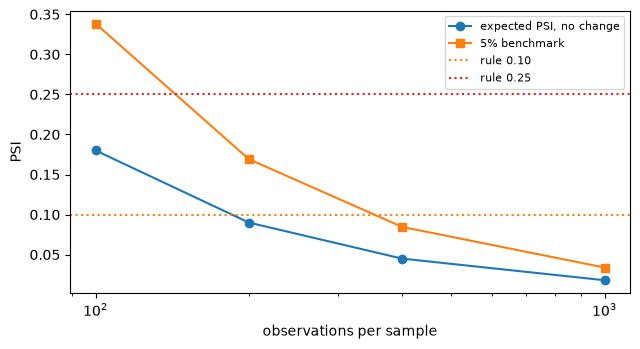

In [3]:
# Expected PSI when nothing changes and the 5% benchmark of the engine, for four sample sizes
from riskvalidation.validation.stability import psi_benchmark

sizes = (100, 200, 400, 1000)
floor = [(1 / n + 1 / n) * 9 for n in sizes]
benchmark = [psi_benchmark(n, n) for n in sizes]
for n, f, b in zip(sizes, floor, benchmark):
    print(f"n = m = {n:4d} | expected PSI under no change {f:.4f} | 5% benchmark {b:.4f}")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(sizes, floor, "o-", label="expected PSI, no change")
ax.plot(sizes, benchmark, "s-", label="5% benchmark")
ax.axhline(0.10, color="tab:orange", linestyle=":", label="rule 0.10")
ax.axhline(0.25, color="tab:red", linestyle=":", label="rule 0.25")
ax.set_xscale("log")
ax.set_xlabel("observations per sample")
ax.set_ylabel("PSI")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

With 100 observations per sample the expected PSI when nothing changes is 0.1800, already above the 0.10 rule, and the 5% benchmark is 0.3384, above even the 0.25 rule. With 1,000 observations the floor falls to 0.0180 and the benchmark to 0.0338. The two lines fall with the sample size while the dotted rules stay put, so a fixed band cuts through the noise at small samples and sits far above the signal at large ones. The benchmark is the only one of the three that moves with the information in the data.

### Step 2: what a shift is worth in PSI units

The generator `TwoSample` states the population distribution of both samples in its `truth()`, so the PSI of a shift can be computed with no sampling by `population_psi`. The sample size at which a rule of thumb equals the 5% benchmark follows from $(2/n)\,\chi^2_{0.95,\,9} = \text{band}$. The next cell prints the population PSI of each rung of the ladder and that sample size for both rules.

In [4]:
# Population PSI of each shift of the ladder and the sample size at which each rule equals the benchmark
from riskvalidation.generators.drift import TwoSample, population_psi

for shift in ladder:
    truth = TwoSample(1000, 1000, shift=shift).truth()
    psi_pop = population_psi(truth["bins_base"], truth["bins_target"])
    print(f"shift {shift:4.2f} | population PSI {psi_pop:.4f}")
critical = stats.chi2.ppf(0.95, 9)
for band in (0.10, 0.25):
    print(f"rule of thumb {band:.2f} | equals the 5% benchmark at n = m = {2 * critical / band:.0f}")

shift 0.00 | population PSI 0.0000
shift 0.05 | population PSI 0.0024
shift 0.10 | population PSI 0.0096
shift 0.20 | population PSI 0.0383
shift 0.30 | population PSI 0.0861
shift 0.50 | population PSI 0.2377
rule of thumb 0.10 | equals the 5% benchmark at n = m = 338
rule of thumb 0.25 | equals the 5% benchmark at n = m = 135


A shift of half a standard deviation has a population PSI of 0.2377, still under the 0.25 rule, so even an enormous sample would not trip that band at that shift. A shift of 0.2 standard deviations is worth only 0.0383. The rules and the benchmark agree at samples of 338 observations for the 0.10 rule and 135 for the 0.25 rule: below those sizes the rule is stricter than the benchmark and fires on noise, above them it is laxer and misses real shifts.

### Step 3: three datasets, three readings

`stability_psi` takes the bin counts of the two samples and returns a `TestResult` with the PSI as its metric, the chi-square p-value, the conventional band in its notes and the 5% benchmark in its extras. The next cell draws three datasets with a fixed seed: two samples of 100 with no change, two of 1,000 with no change and two of 1,000 whose mean differs by 0.2 standard deviations.

In [5]:
# Draw three datasets and read the PSI, its conventional band, its benchmark and its p-value for each
from riskvalidation.validation.stability import stability_psi

cases = (("100 vs 100", TwoSample(100, 100)), ("1000 vs 1000", TwoSample(1000, 1000)),
         ("1000 vs 1000, shift 0.2", TwoSample(1000, 1000, shift=0.2)))
for label, generator in cases:
    sample = generator.draw(np.random.default_rng(31))
    result = stability_psi(sample["expected_counts"], sample["actual_counts"])
    print(f"{label:34s} PSI {result.metric:.4f} | band {result.extras['band']}")
    print(f"{'':34s} benchmark {result.extras['benchmark_05']:.4f} | p {result.p_value:.4f}")

100 vs 100                         PSI 0.2796 | band significant change
                                   benchmark 0.3384 | p 0.1231
1000 vs 1000                       PSI 0.0146 | band little change
                                   benchmark 0.0338 | p 0.6047
1000 vs 1000, shift 0.2            PSI 0.0392 | band little change
                                   benchmark 0.0338 | p 0.0205


Two samples of 100 with nothing changed give a PSI of 0.2796, which the conventional band calls a significant change, while the benchmark of 0.3384 and a p-value of 0.1231 correctly see noise. The samples of 1,000 with no change give 0.0146 and a p-value of 0.6047. With a real shift of 0.2 standard deviations the PSI is 0.0392, in the band called little change, but above the benchmark of 0.0338 with a p-value of 0.0205: the band misses what the test sees. The same index leads to opposite errors in the two directions.

### Step 4: the false alarms of the rules, measured

The next cell runs the PSI test on two samples with no change at four sample sizes, 4,000 repetitions each, with the engine's `simulate` and two extra rules built with `metric_above`: the PSI exceeds 0.10 and the PSI exceeds 0.25. It prints the false-alarm rate of both rules and of the 5% benchmark at each size and draws them.

n = m =  100 | PSI > 0.10 0.857 | PSI > 0.25 0.227 | benchmark at 5% 0.075
n = m =  200 | PSI > 0.10 0.379 | PSI > 0.25 0.004 | benchmark at 5% 0.061
n = m =  400 | PSI > 0.10 0.021 | PSI > 0.25 0.000 | benchmark at 5% 0.052
n = m = 1000 | PSI > 0.10 0.000 | PSI > 0.25 0.000 | benchmark at 5% 0.049


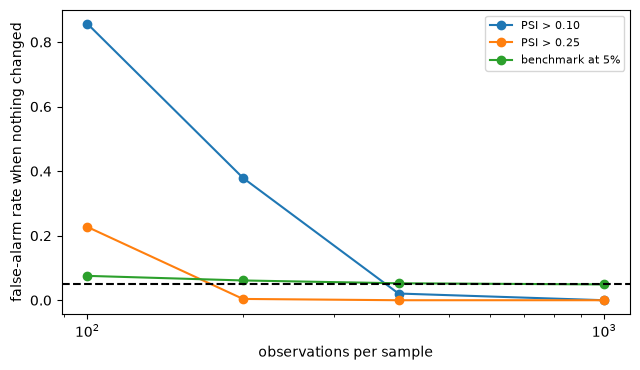

In [6]:
# Measure the false-alarm rate of both rules of thumb and of the benchmark at four sample sizes
from riskvalidation.harness.run import metric_above, simulate

rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
names = {"metric>0.1": "PSI > 0.10", "metric>0.25": "PSI > 0.25", "p<0.05": "benchmark at 5%"}
alarms = {rule: [] for rule in names}
for n in (100, 200, 400, 1000):
    run = simulate("stability.psi", TwoSample(n, n), n_rep=4000, seed=2026, rules=rules)
    for rule in names:
        alarms[rule].append(run.rates[rule])
    print(f"n = m = {n:4d} |", " | ".join(f"{names[rule]} {alarms[rule][-1].rate:.3f}" for rule in names))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for rule, label in names.items():
    ax.plot((100, 200, 400, 1000), [r.rate for r in alarms[rule]], "o-", label=label)
ax.axhline(0.05, color="black", linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("observations per sample")
ax.set_ylabel("false-alarm rate when nothing changed")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

With samples of 100 the 0.10 rule fires 0.857 of the time when nothing changed and the 0.25 rule 0.227, against 0.075 for the benchmark. At 200 the rules give 0.379 and 0.004, at 400 they give 0.021 and 0.000, and at 1,000 both are silent. The benchmark stays near its level at every size, between 0.075 and 0.049, a little above 5% for the smallest samples because its chi-square form is asymptotic. The rules go from raising a false alarm in six cases out of seven to never raising one, and they cross the 5% line in between.

### Step 5: power along the ladder

For samples of 1,000, the next cell moves the mean of the current sample along the ladder and simulates the PSI with its two rules and its benchmark, the chi-square test of homogeneity and the Kolmogorov-Smirnov test, 1,000 repetitions per rung. It prints the rate at which each fires and draws the five curves. The first rung, with no shift, is the false-alarm rate and the others are power.

PSI > 0.10                   [0.0, 0.0, 0.0, 0.026, 0.523, 1.0]
PSI > 0.25                   [0.0, 0.0, 0.0, 0.0, 0.0, 0.557]
PSI benchmark                [0.042, 0.101, 0.262, 0.898, 1.0, 1.0]
chi-square                   [0.041, 0.097, 0.257, 0.894, 1.0, 1.0]
Kolmogorov-Smirnov           [0.051, 0.126, 0.49, 0.968, 1.0, 1.0]


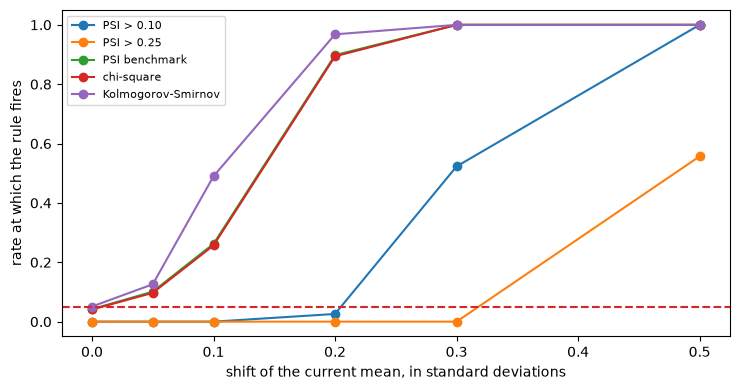

In [7]:
# Power of each rule and test along the ladder of shifts, samples of 1000
curves = {"PSI > 0.10": ("stability.psi", "metric>0.1"), "PSI > 0.25": ("stability.psi", "metric>0.25"),
          "PSI benchmark": ("stability.psi", "p<0.05"), "chi-square": ("stability.chi2", "p<0.05"),
          "Kolmogorov-Smirnov": ("stability.ks", "p<0.05")}
power = {name: [] for name in curves}
for shift in ladder:
    row = rows[f"stability.psi@s{shift:g}"]
    sample_gen = TwoSample(1000, 1000, shift=shift)
    runs = {}
    for test in ("stability.psi", "stability.chi2", "stability.ks"):
        runs[test] = simulate(test, sample_gen, n_rep=1000, seed=row["seed"], rules=rules)
    for name, (test, rule) in curves.items():
        power[name].append(runs[test].rates[rule].rate)
fig, ax = plt.subplots(figsize=(7.5, 4))
for name in curves:
    ax.plot(ladder, power[name], "o-", label=name)
    print(f"{name:28s}", [round(p, 3) for p in power[name]])
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("shift of the current mean, in standard deviations")
ax.set_ylabel("rate at which the rule fires")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

At a shift of 0.2 standard deviations the benchmark fires 0.898 of the time, the chi-square test 0.894 and the Kolmogorov-Smirnov test 0.968, while the 0.10 rule fires 0.026 and the 0.25 rule never. The rule of 0.10 needs a shift of 0.3 to reach 0.523, and the rule of 0.25 does not fire more than half the time even at 0.5, with 0.557. At 0.1 the Kolmogorov-Smirnov test already catches 0.490 against 0.262 for the benchmark. With these samples the rules of thumb are nearly blind where the tests see, and a shift they miss is invisible only to them.

### Step 6: Table 4 of the paper, rerun

Yurdakul and Naranjo (2020) printed, with 10,000 runs, the rate at which the two rules of thumb and the chi-square benchmark fire for six pairs of sample sizes and three shifts. The next cell reruns the equal-sample cells (100, 200 and 400 observations; shifts of 0 and a quarter of a standard deviation) with 4,000 repetitions and a new seed, and sets each rate against the published one with `agrees_with_published`. The last line gives the count of the committed table.

In [8]:
# Rerun cells of Table 4 of Yurdakul and Naranjo with the engine and set them against the published rates
from riskvalidation.harness.rates import agrees_with_published

cells = {(c["row"], c["column"]): c["published"] for c in golden["cells"]}
for size_m, size_n in ((100, 100), (200, 200), (400, 400)):
    for shift in (0.0, 0.25):
        run = simulate("stability.psi", TwoSample(size_n, size_m, shift=shift), n_rep=4000, seed=7, rules=rules)
        for rule, column in (("metric>0.1", "PSI > 0.10"), ("metric>0.25", "PSI > 0.25"), ("p<0.05", "chi-square")):
            published = cells[(f"m {size_m}, n {size_n}", f"shift {shift:g} SD, {column}")]
            ok, z = agrees_with_published(run.rates[rule], published, golden["runs_published"])
            print(f"m {size_m}, n {size_n} | {shift:4.2f} | {column:10s} | published {published:.3f}", end=" | ")
            print(f"new run {run.rates[rule].rate:.4f} | z {z:+.2f} | {ok}")
print("cells of the table in the file:", len(golden["cells"]), "| that agree:", golden["agree"])

m 100, n 100 | 0.00 | PSI > 0.10 | published 0.849 | new run 0.8588 | z +1.47 | True
m 100, n 100 | 0.00 | PSI > 0.25 | published 0.233 | new run 0.2268 | z -0.79 | True
m 100, n 100 | 0.00 | chi-square | published 0.076 | new run 0.0745 | z -0.30 | True
m 100, n 100 | 0.25 | PSI > 0.10 | published 0.943 | new run 0.9380 | z -1.14 | True
m 100, n 100 | 0.25 | PSI > 0.25 | published 0.459 | new run 0.4552 | z -0.40 | True
m 100, n 100 | 0.25 | chi-square | published 0.218 | new run 0.2220 | z +0.52 | True
m 200, n 200 | 0.00 | PSI > 0.10 | published 0.369 | new run 0.3550 | z -1.55 | True
m 200, n 200 | 0.00 | PSI > 0.25 | published 0.004 | new run 0.0032 | z -0.65 | True
m 200, n 200 | 0.00 | chi-square | published 0.057 | new run 0.0555 | z -0.35 | True
m 200, n 200 | 0.25 | PSI > 0.10 | published 0.775 | new run 0.7800 | z +0.64 | True
m 200, n 200 | 0.25 | PSI > 0.25 | published 0.085 | new run 0.0910 | z +1.14 | True
m 200, n 200 | 0.25 | chi-square | published 0.360 | new run 0.36

All 18 rerun cells agree with the paper, with standardised differences between -1.55 and +1.47. The paper's reading holds in them: the 0.10 rule has a type I error of 0.859 at 100 observations and 0.020 at 400, the 0.25 rule's falls from 0.227 to 0.000, and the chi-square benchmark stays near 5%, from 0.075 to 0.051. In the committed table, built with the paper's full set of 54 cells, 50 agree. The qualitative findings reproduce, which is what the claim needs.

### Step 7: drift is not miscalibration

The `calibration` panel shifts the covariates of a logistic portfolio by the same amounts while the model keeps its true coefficients, so its PDs stay right for every obligor. A drift alarm and a calibration alarm answer different questions, and the second should stay quiet. The next cell simulates Hosmer-Lemeshow and Spiegelhalter along the ladder, 500 repetitions per rung, and draws their rejection rates against the nominal 5%.

pd.hosmer_lemeshow   [0.042, 0.064, 0.038, 0.056, 0.064, 0.046]
pd.spiegelhalter     [0.048, 0.044, 0.048, 0.056, 0.064, 0.054]


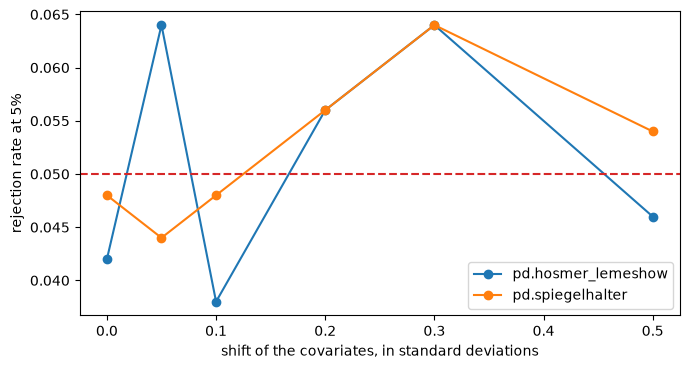

In [9]:
# Shift the covariates of a right logistic model and measure Hosmer-Lemeshow and Spiegelhalter
from riskvalidation.generators.scores import LogisticPortfolio

fig, ax = plt.subplots(figsize=(7, 3.8))
for test in ("pd.hosmer_lemeshow", "pd.spiegelhalter"):
    rates = []
    for shift in ladder:
        row = rows[f"{test}@s{shift:g}"]
        gen = LogisticPortfolio(**out["generators"][row["generator"]]["config"])
        rates.append(simulate(test, gen, n_rep=500, seed=row["seed"]).rates["p<0.05"].rate)
    ax.plot(ladder, rates, "o-", label=test)
    print(f"{test:20s}", [round(r, 3) for r in rates])
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("shift of the covariates, in standard deviations")
ax.set_ylabel("rejection rate at 5%")
ax.legend()
fig.tight_layout()
plt.show()

Both calibration tests stay at the level of a right model along the whole ladder: Hosmer-Lemeshow between 0.038 and 0.064 and Spiegelhalter between 0.044 and 0.064, with 500 repetitions per rung, where the Monte Carlo error is about one point. The covariates drifted by half a standard deviation, a shift that the Kolmogorov-Smirnov test catches every time in the previous step, and yet the model's PDs are still right for each obligor. A validator should therefore read a drift alarm as a reason to look, not as evidence of miscalibration.

## Results

**Answer:** With 100 observations per sample and nothing changed, the 0.10 rule of thumb fires 0.857 of the time and the 0.25 rule 0.227, against 0.075 for the 5% benchmark; with 1,000 observations both rules are silent and the benchmark stays at 0.049. For power with samples of 1,000, a shift of 0.2 standard deviations is detected 0.898 of the time by the benchmark and 0.968 by the Kolmogorov-Smirnov test, but only 0.026 by the 0.10 rule and never by the 0.25 rule, which reaches 0.557 at a shift of 0.5.

- **The noise floor depends on the sample size.** The expected PSI under no change is 0.1800 for samples of 100 and 0.0180 for 1,000; the rules and the benchmark agree at 338 and 135 observations.
- **The engine reproduces the paper.** All 18 rerun cells of Table 4 agree, with standardised differences from -1.55 to +1.47.
- **Drift is not miscalibration.** With a right model, Hosmer-Lemeshow stays between 0.038 and 0.064 as the covariates shift.

How the same rules behave when the shift comes from a leak or a decaying score is the topic of the next notebook.

## Summary

- The PSI has a noise floor of $(1/n + 1/m)(B-1)$ and a 5% benchmark of $(1/n + 1/m)\chi^2_{0.95,\,B-1}$, both of which depend on the sample sizes; a fixed band cannot.
- The 0.10 rule raises false alarms most of the time with samples of 100 and none with 1,000, and the 0.25 rule rarely fires even for a shift of half a standard deviation.
- The chi-square benchmark keeps its level and the Kolmogorov-Smirnov test is the most powerful of the five on a mean shift.
- The engine reproduces the equal-sample cells of the paper's Table 4.
- A drift alarm says nothing about calibration when the model is right.

**What to try next.** Rerun step 4 with a base sample of 400 and a current sample of 100 and see which rule changes most, then read notebook 06.

## References

- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4): the rules of thumb, Theorem 3.3, the benchmark and Table 4. https://doi.org/10.21314/JRMV.2020.227
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.